# Imports and Data

In [39]:
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [11]:
# Load the extracted COBRA data
data = np.load("PWR_INP.txt_temperature_arrays.npz")

# Extract individual arrays
z_coordinates = data["z_coordinates"]
fuel_average = data["fuel_average"]
fuel_centreline = data["fuel_centreline"]
clad_inner_surface = data["clad_inner_surface"]
clad_outer_surface = data["clad_outer_surface"]
coolant_temperature = data["coolant_temperature"]

print("COBRA data loaded successfully!")
print("Number of axial positions:", len(z_coordinates))

for lists in [z_coordinates, fuel_centreline, fuel_average, clad_inner_surface, clad_outer_surface]:
    print(len(lists))

COBRA data loaded successfully!
Number of axial positions: 18
18
18
18
18
18


In [17]:
plt.rcParams.update({
    "font.size": 14,        # default text size
    "axes.titlesize": 16,   # title size
    "axes.labelsize": 15,   # axis labels
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

plt.rcParams.update({
    "font.family": "Times New Roman",  # Use Times New Roman for all text
    "mathtext.fontset": "custom",      # Use custom font for math
    "mathtext.rm": "Times New Roman",  # Roman font in math
    "mathtext.it": "Times New Roman:italic",  # Italic font in math
    "mathtext.bf": "Times New Roman:bold",    # Bold font in math
    "text.usetex": False
})

# Fitting

In [85]:
def sinusoidal_model(x, intercept, scale_factor, coefficient):
    return intercept+scale_factor*np.sin(x*coefficient)

def cosinusoidal_model(x, intercept, scale_factor, coefficient):
    return intercept + scale_factor * np.cos(x*coefficient)

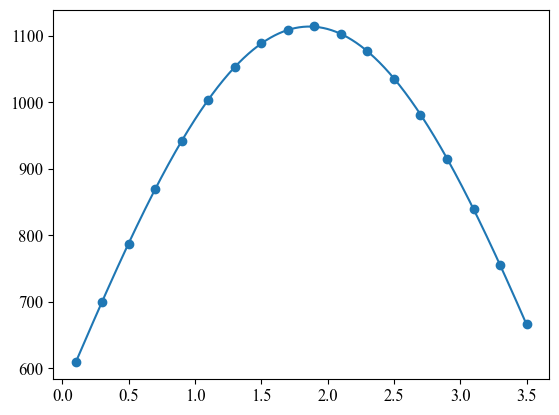

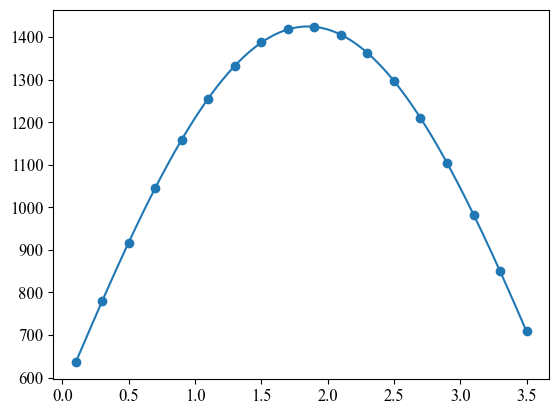

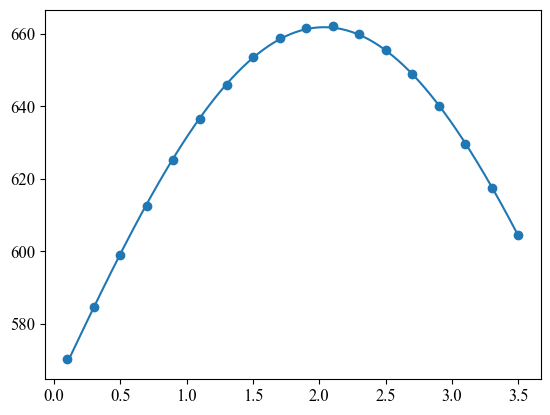

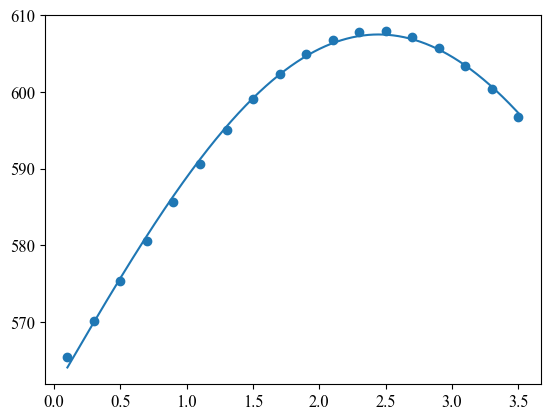

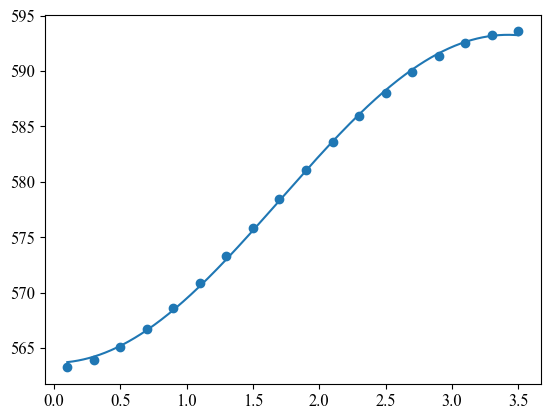

In [86]:
pops = []
covs = []
residuals = []

xrange = np.linspace(z_coordinates[0], z_coordinates[-1], 1000)

datasets = [fuel_average, fuel_centreline, clad_inner_surface, clad_outer_surface]

for set in datasets:
    p0 = [0,np.max(set),z_coordinates[-1]/np.pi]

    pop, cov = curve_fit(sinusoidal_model,
                     z_coordinates,
                     set,
                     p0 = p0,
                     maxfev = 50000)

    residual = set - sinusoidal_model(z_coordinates, *pop)

    plt.figure(1)
    plt.scatter(z_coordinates, set)

    plt.plot(xrange, sinusoidal_model(xrange, *pop))

    plt.show()

    pops.append(pop)
    covs.append(cov)
    residuals.append(residual)

p0_coolant = [0, np.max(coolant_temperature), z_coordinates[-1]/np.pi]

pop_coolant, cov_coolant = curve_fit(cosinusoidal_model,
                                     z_coordinates,
                                     coolant_temperature,
                                     p0 = p0_coolant,
                                     maxfev = 50000)

residual_coolant = coolant_temperature - cosinusoidal_model(z_coordinates, *pop_coolant)

plt.figure(1)
plt.scatter(z_coordinates, coolant_temperature)

plt.plot(xrange, cosinusoidal_model(xrange, *pop_coolant))

plt.show()

pops.append(pop_coolant)
covs.append(cov_coolant)
residuals.append(residual_coolant)

datasets.append(coolant_temperature)

# Plot 1: Temperature Distributions

In [87]:
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba

color_list = ["#D55E00", "#0072B2", "#009E73", "#E69F00", "#CC79A7"]
marker_list = ["o", "D", "s", "h", "v"]

labels = [
    "Fuel average",
    "Fuel centreline",
    "Clad inner surface",
    "Clad outer surface",
    "Coolant"
]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels):

    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='--',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements.append(((line, marker_handle), label))

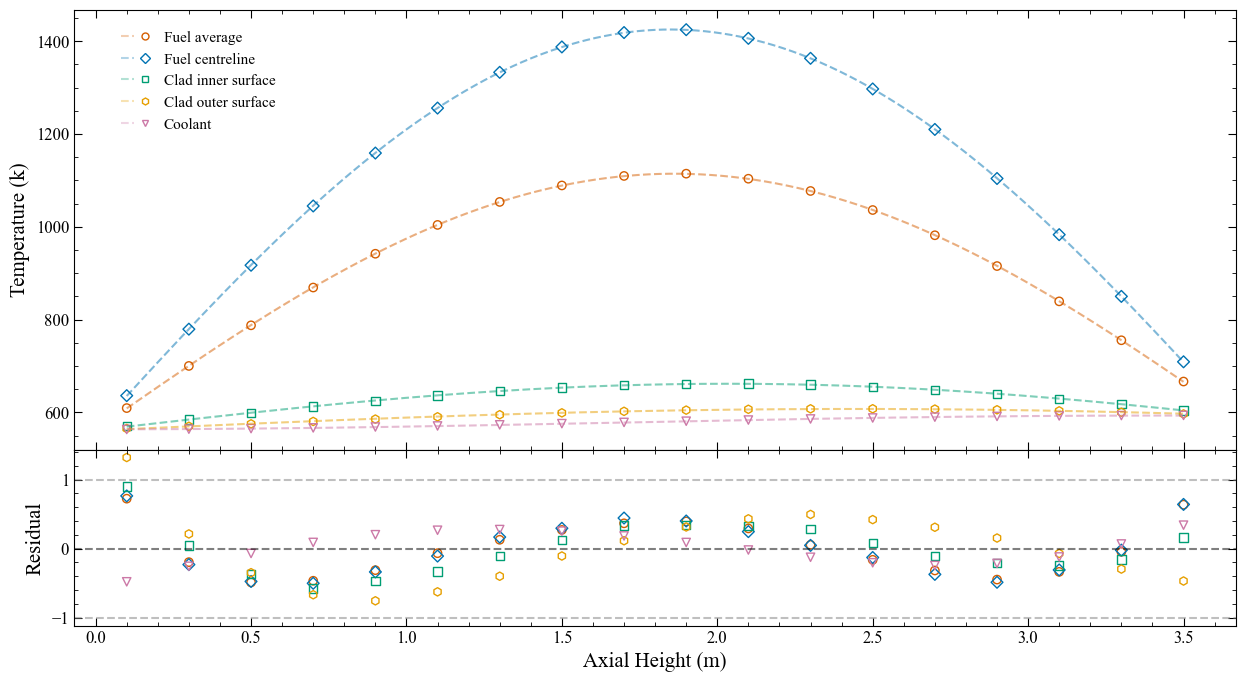

In [93]:
#######
# Setup
#######

fig = plt.figure(figsize= (15,8))

gs = fig.add_gridspec(
    2,1,
    height_ratios = [5,2],
    hspace = 0
)

ax_main = fig.add_subplot(gs[0])
ax_res = fig.add_subplot(gs[1])


###########
# Main Plot
###########

for ydata, pop, colour, marker in zip(
    [fuel_average, fuel_centreline, clad_inner_surface, clad_outer_surface], pops[:-1], color_list[:-1], marker_list[:-1]):

    ax_main.scatter(z_coordinates, ydata,
                    marker = marker, color = colour, facecolor = "none")

    ax_main.plot(xrange, sinusoidal_model(xrange, *pop),
                 color = colour, marker = "none", linestyle = "--", alpha = 0.5)

ax_main.scatter(z_coordinates, coolant_temperature,
                marker = marker_list[-1], color = color_list[-1], facecolor = "none")

ax_main.plot(xrange, cosinusoidal_model(xrange, *pop_coolant),
             color = color_list[-1], marker = "none", linestyle = "--", alpha = 0.5)

ax_main.legend(
    handles=[item[0] for item in legend_elements],
    labels=[item[1] for item in legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.03, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

###############
# Residual Plot
###############


for residual, colour, marker in zip(
    residuals, color_list, marker_list):
    ax_res.scatter(z_coordinates, residual,
                   marker = marker, color = colour, facecolor = "none")

ax_res.axhline(0, linestyle = "--", color = "black", alpha = 0.5)
ax_res.axhline(1, linestyle = "--", color = "grey", alpha = 0.5)
ax_res.axhline(-1, linestyle = "--", color = "grey", alpha = 0.5)

ax_res.set_ylabel("Residual")


#####################
# Formatting and Save
#####################

ax_res.set_xlabel("Axial Height (m)")
ax_main.set_ylabel("Temperature (k)")

for ax in [ax_main, ax_res]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels()+ ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_Temperature_Plot.png",
    dpi = 250,
    bbox_inches = "tight"
)

plt.show()